#Comparing Segmentation masks of FCN and Dilated Convolutions (DeepLab)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
def decode_seg_map(mask):
    """Converts a class index mask (H, W) into an RGB image for display."""
    mask_np = mask.cpu().numpy().astype(np.uint8)
    # Mask out border/void pixels (class 255) to background (class 0)
    mask_np[mask_np >= len(VOC_COLORMAP)] = 0

    rgb_mask = VOC_COLORMAP[mask_np]
    return rgb_mask

In [ ]:
def get_dataloaders(batch_size=4, image_size=(256, 256)):
    """Loads PASCAL VOC 2012 Segmentation validation dataset."""
    transform = T.Compose([
        T.Resize(image_size),
        T.ToTensor(),
        T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ])

    target_transform = T.Compose([
        T.Resize(image_size, interpolation=T.InterpolationMode.NEAREST),
        T.PILToTensor(),
    ])

    val_dataset = datasets.VOCSegmentation(
        root="./data",
        year="2012",
        image_set="val",
        download=True,
        transform=transform,
        target_transform=target_transform
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=2,
        pin_memory=True
    )

    return val_loader

In [ ]:
def denormalize(tensor):
    """Reverses ImageNet normalization for visualization."""
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])

    img = tensor.cpu().numpy().transpose(1, 2, 0)
    img = (img * std + mean).clip(0, 1)
    return img

In [ ]:
# PASCAL VOC 21-Class Color Palette for clear segmentation rendering
VOC_COLORMAP = np.array([
    [0, 0, 0], [128, 0, 0], [0, 128, 0], [128, 128, 0],
    [0, 0, 128], [128, 0, 128], [0, 128, 128], [128, 128, 128],
    [64, 0, 0], [192, 0, 0], [64, 128, 0], [192, 128, 0],
    [64, 0, 128], [192, 0, 128], [64, 128, 128], [192, 128, 128],
    [0, 64, 0], [128, 64, 0], [0, 192, 0], [128, 192, 0],
    [0, 64, 128]
], dtype=np.uint8)

In [ ]:
def plot_and_save_comparisons(images, targets, norm_preds, dil_preds, num_samples=3, save_path="segmentation_comparison.png"):
    """
    Plots side-by-side visual comparisons of predictions from standard and dilated CNNs.
    """
    num_samples = min(num_samples, len(images))
    fig, axes = plt.subplots(num_samples, 4, figsize=(16, 4 * num_samples))

    # Ensure 2D grid indexing even if num_samples == 1
    if num_samples == 1:
        axes = np.expand_dims(axes, axis=0)

    for idx in range(num_samples):
        # 1. Original RGB Image
        orig_img = denormalize(images[idx])
        axes[idx, 0].imshow(orig_img)
        axes[idx, 0].set_title("Input Image", fontsize=12)
        axes[idx, 0].axis("off")

        # 2. Ground Truth Mask
        gt_mask = decode_seg_map(targets[idx])
        axes[idx, 1].imshow(gt_mask)
        axes[idx, 1].set_title("Ground Truth", fontsize=12)
        axes[idx, 1].axis("off")

        # 3. Standard CNN (FCN) Mask
        norm_mask = decode_seg_map(norm_preds[idx])
        axes[idx, 2].imshow(norm_mask)
        axes[idx, 2].set_title("Standard CNN (FCN)", fontsize=12)
        axes[idx, 2].axis("off")

        # 4. Dilated CNN (DeepLabV3) Mask
        dil_mask = decode_seg_map(dil_preds[idx])
        axes[idx, 3].imshow(dil_mask)
        axes[idx, 3].set_title("Dilated CNN (DeepLabV3)", fontsize=12)
        axes[idx, 3].axis("off")

    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    print(f"\nsaved successfully to: '{save_path}'")
    plt.show()

In [ ]:
import torch
import torch.nn as nn
import torchvision.models.segmentation as seg_models
import torchvision.transforms as T
import torchvision.datasets as datasets
from torch.utils.data import DataLoader


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using Device: {device}\n" + "=" * 50)

# 1. Load Prebuilt Models
print("Loading pre-trained PyTorch segmentation models...")
normal_conv_model = seg_models.fcn_resnet50(
    weights=seg_models.FCN_ResNet50_Weights.DEFAULT
).to(device).eval()

dilated_conv_model = seg_models.deeplabv3_resnet50(
    weights=seg_models.DeepLabV3_ResNet50_Weights.DEFAULT
).to(device).eval()

# 2. Load Validation Batch
val_loader = get_dataloaders(batch_size=4)
images, targets = next(iter(val_loader))

images_dev = images.to(device)
targets_dev = targets.squeeze(1).long().to(device)

Using Device: cpu
Loading pre-trained PyTorch segmentation models...



saved successfully to: 'segmentation_comparison.png'


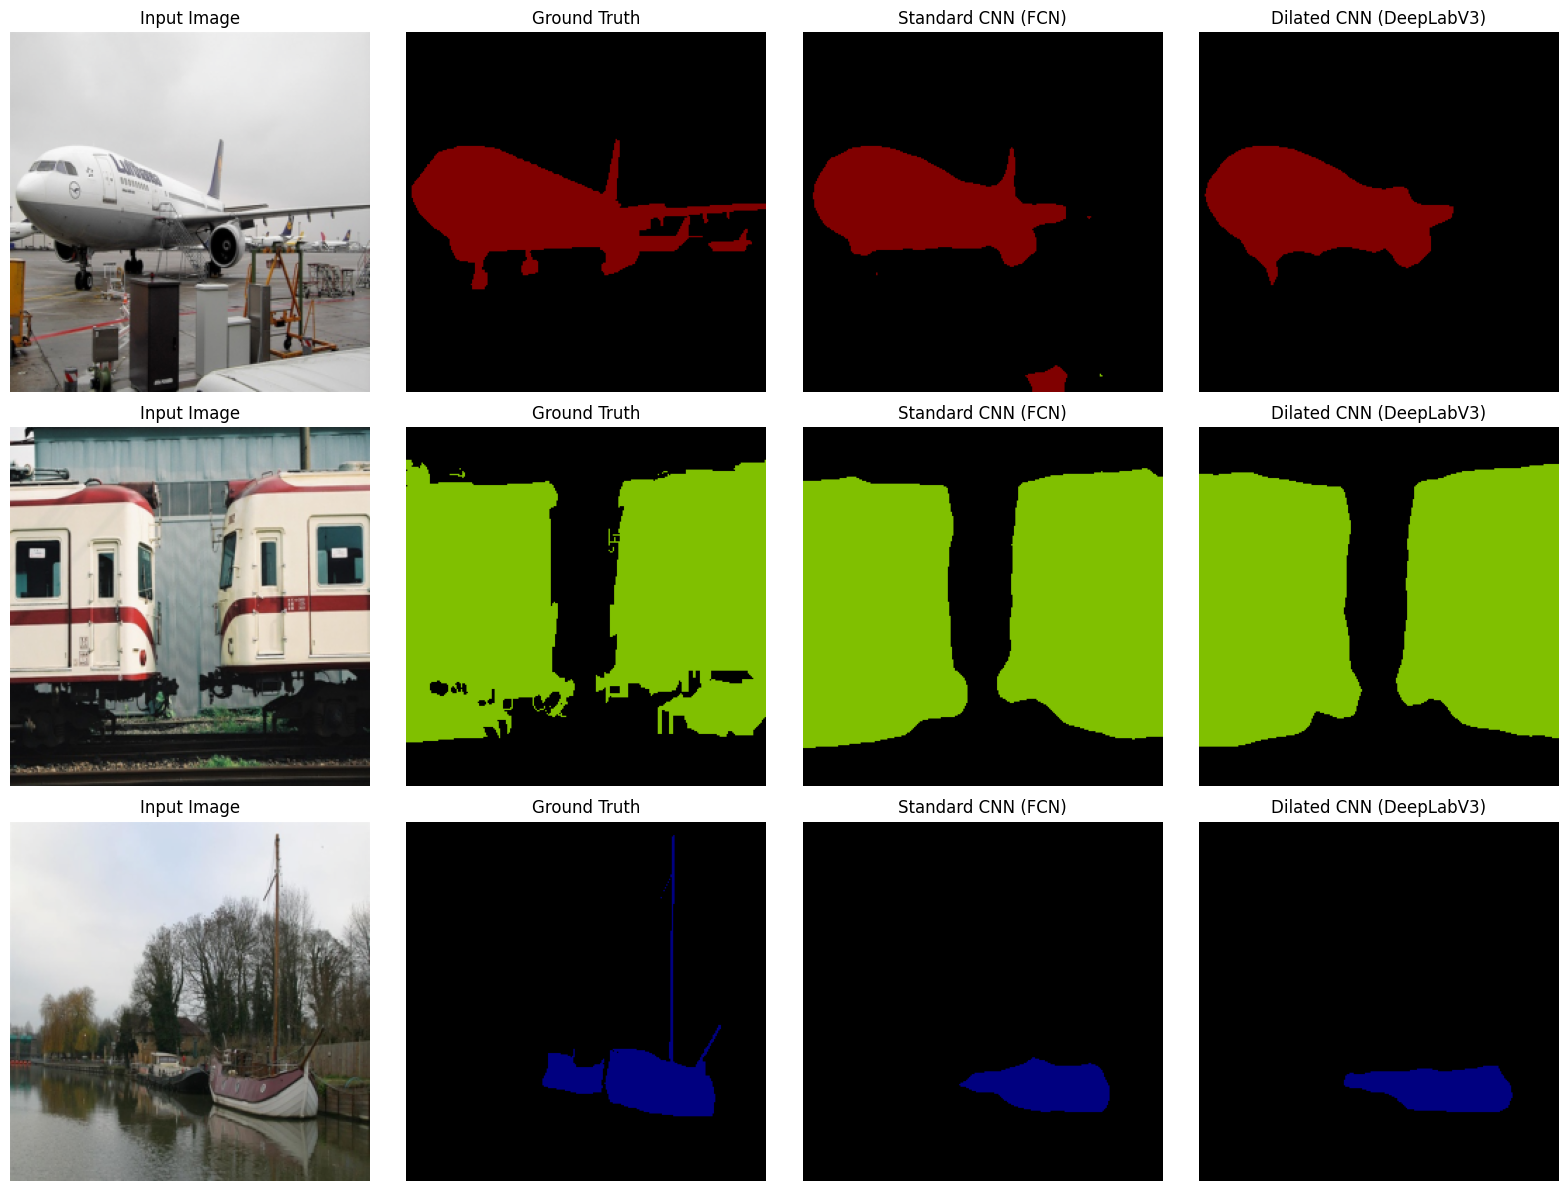

In [ ]:
# 3. Generate Predictions
with torch.no_grad():
    norm_logits = normal_conv_model(images_dev)['out']
    norm_preds = norm_logits.argmax(dim=1)

    dil_logits = dilated_conv_model(images_dev)['out']
    dil_preds = dil_logits.argmax(dim=1)

# 4. Plot and Save Visual Comparison
plot_and_save_comparisons(
    images=images,
    targets=targets_dev.cpu(),
    norm_preds=norm_preds.cpu(),
    dil_preds=dil_preds.cpu(),
    num_samples=3,
    save_path="segmentation_comparison.png"
)